<div align="center">

# WEEK 03
## BASELINE KPIs AND KPI TRACKER

### CadetX Virtual Work Experience
### Heavy Supplier, Inventory & Warehouse Analytics

</div>

---

| | |
|---|---|
| **Prepared by** | Keren Oyem (Data Analyst / Data Scientist) |
| **Sprint** | Week 3 · Fri 6 Nov – Thu 12 Nov 2026 |
| **Deliverable** | Baseline KPI tracker (2019-2024 and latest year) and Phase 1 headline findings |
| **Input** | Schemas `star` and `feat` in `warehouse.duckdb` |
| **Output** | `docs/kpi_tracker.csv` and `docs/kpi_tracker.xlsx` |
| **Tools** | Python, SQL on DuckDB, pandas, matplotlib |

## Purpose

A **baseline** records where the business stands *before* any improvement work. Every later week (and the Week 12 KPI framework with targets) is measured against these numbers.

## Scope

KPIs follow the proposal from Week 1 and cover five areas: **Sales & Finance**, **Customer**, **Supplier & Procurement**, **Product & Inventory**, **Warehouse**. Values are given for each year **2019-2024** and for the whole period (**2019-2024**); the latest year is **2024**.

## Method and conventions

* Revenue counts **delivered** orders only, before GST, in INR crore (1 crore = 10 million).
* Cancelled orders and POs are excluded from revenue, delay and lead-time KPIs, and used only for cancellation rates.
* Invoices with a re-issued `invoice_id` are excluded from payment KPIs (their payments cannot be assigned safely).
* Each KPI row carries a **basis** column: `pooled` (computed on all years together), `avg of years` (mean of the six yearly values) or `snapshot` (single point in time).
* Reference date: **31 Dec 2024**.

## Contents

0. Setup · 1. Sales & Finance · 2. Customer · 3. Supplier & Procurement · 4. Product & Inventory · 5. Warehouse · 6. KPI tracker · 7. Headline view · 8. Summary

## 0. Setup

**Objective.** Open the database, confirm the feature tables exist and define two helpers.

* `run(sql)` runs a query and returns numbers as numbers.
* `register(df, area, spec)` turns a yearly result table into tracker rows. `spec` names each KPI as `column: (KPI name, unit, basis)`.

In [1]:
import os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

try:
    con.close()
except Exception:
    pass
con = duckdb.connect("warehouse.duckdb")

n_feat = con.execute("SELECT COUNT(*) FROM duckdb_tables() WHERE schema_name = 'feat'").fetchone()[0]
assert n_feat == 8, "Feature tables not found. Run 03_feature_engineering.ipynb first."

PERIODS = ["2019", "2020", "2021", "2022", "2023", "2024", "2019-2024"]
tracker_parts = []


def run(sql):
    """Run a query; convert every column except `period` to numbers."""
    df = con.execute(sql).df()
    for col in df.columns:
        if col != "period":
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df


def add_avg_row(df, cols):
    """Append a 2019-2024 row = mean of the yearly rows (for KPIs that are not poolable)."""
    row = df.loc[df["period"] != "2019-2024", cols].mean().to_dict()
    row["period"] = "2019-2024"
    return pd.concat([df, pd.DataFrame([row])], ignore_index=True)


def register(df, area, spec):
    """Add KPI rows to the tracker. spec = {column: (kpi_name, unit, basis)}."""
    wide = df.set_index("period")[list(spec)].T.reindex(columns=PERIODS)
    wide.insert(0, "basis", [spec[c][2] for c in wide.index])
    wide.insert(0, "unit", [spec[c][1] for c in wide.index])
    wide.insert(0, "kpi", [spec[c][0] for c in wide.index])
    wide.insert(0, "area", area)
    wide = wide.reset_index(drop=True)
    tracker_parts.append(wide)
    return wide


print("Connected. Feature tables found:", n_feat)

Connected. Feature tables found: 8


**Reading the output.** `Connected. Feature tables found: 8`. If the assertion fails, run `03_feature_engineering.ipynb` first.

## 1. Sales & Finance KPIs

**Objective.** Measure revenue, margin, order value, cancellations, delivery speed and cash collection.

| KPI | Definition |
|---|---|
| Revenue | Sum of delivered order value before GST |
| Gross margin % | (Revenue - cost at master unit cost) / Revenue |
| Average order value (AOV) | Revenue / delivered orders |
| SO cancellation rate | Cancelled orders / orders placed |
| Order-to-delivery days | Mean days from order to delivery (delivered orders) |
| Collection rate | Payments received / invoiced (unambiguous invoices) |
| DSO (proxy) | Outstanding / invoiced x 365. A simplification: a true period-end DSO needs a payment timeline (Week 8) |
| Overdue receivables % | Overdue outstanding at 31 Dec 2024 / total outstanding |
| Average days to pay | Mean days to pay, fully paid invoices |
| Late payment rate | Share of fully paid invoices paid after the due date |

In [2]:
sales = run("""
    SELECT COALESCE(CAST(order_year AS VARCHAR), '2019-2024') AS period,
           COUNT(*)                                         AS orders_placed,
           COUNT(*) FILTER (WHERE NOT is_cancelled)         AS orders_delivered,
           SUM(revenue_before_gst) FILTER (WHERE NOT is_cancelled) / 1e7 AS revenue_cr,
           SUM(units) FILTER (WHERE NOT is_cancelled)       AS units_sold,
           SUM(gross_margin) FILTER (WHERE NOT is_cancelled) / 1e7 AS gross_margin_cr,
           100.0 * SUM(gross_margin) FILTER (WHERE NOT is_cancelled)
                 / SUM(revenue_before_gst) FILTER (WHERE NOT is_cancelled) AS gross_margin_pct,
           SUM(revenue_before_gst) FILTER (WHERE NOT is_cancelled)
                 / COUNT(*) FILTER (WHERE NOT is_cancelled)  AS aov_inr,
           100.0 * COUNT(*) FILTER (WHERE is_cancelled) / COUNT(*) AS so_cancellation_rate_pct,
           AVG(order_to_delivery_days)                      AS avg_order_to_delivery_days
    FROM feat.feat_sales_order
    GROUP BY GROUPING SETS ((order_year), ())
    ORDER BY period
""")

sales_spec = {
    "orders_placed":     ("Orders placed", "count", "pooled"),
    "orders_delivered":  ("Orders delivered", "count", "pooled"),
    "revenue_cr":        ("Revenue (before GST)", "INR crore", "pooled"),
    "units_sold":        ("Units sold", "units", "pooled"),
    "gross_margin_cr":   ("Gross margin", "INR crore", "pooled"),
    "gross_margin_pct":  ("Gross margin %", "%", "pooled"),
    "aov_inr":           ("Average order value", "INR", "pooled"),
    "so_cancellation_rate_pct": ("SO cancellation rate", "%", "pooled"),
    "avg_order_to_delivery_days": ("Order-to-delivery days", "days", "pooled"),
}
register(sales, "Sales & Finance", sales_spec)

# Consistency check: the pooled revenue must equal the sum of the six years
yearly = sales[sales.period != "2019-2024"]["revenue_cr"].sum()
pooled = sales.loc[sales.period == "2019-2024", "revenue_cr"].iloc[0]
assert abs(yearly - pooled) < 1e-6, "Pooled revenue differs from the sum of the years"

sales.round(2)

,period,orders_placed,orders_delivered,revenue_cr,units_sold,gross_margin_cr,gross_margin_pct,aov_inr,so_cancellation_rate_pct,avg_order_to_delivery_days
0,2019,3336,3031,387.00,207925.0,83.44,21.56,1276811.81,9.14,8.09
1,2019-2024,20000,18033,2295.90,1234939.0,495.00,21.56,1273165.17,9.84,8.06
2,2020,3358,3038,391.75,212007.0,84.51,21.57,1289510.24,9.53,8.08
3,2021,3365,3038,385.25,208269.0,83.12,21.58,1268097.31,9.72,8.04
4,2022,3279,2948,381.63,202242.0,82.11,21.52,1294534.67,10.09,8.08
5,2023,3346,3022,382.47,204638.0,82.46,21.56,1265610.63,9.68,8.08
6,2024,3316,2956,367.80,199858.0,79.36,21.58,1244247.48,10.86,8.00


**Reading the output.** One row per year plus `2019-2024`. Check three things: revenue by year follows the order volume; gross margin % is a sensible percentage (below 100); the cancellation rate is near the 9.8% found in Week 2. The built-in assertion confirms pooled revenue equals the sum of the six years.

In [3]:
finance = run("""
    SELECT COALESCE(CAST(invoice_year AS VARCHAR), '2019-2024') AS period,
           COUNT(*) AS invoices,
           SUM(grand_total) FILTER (WHERE NOT invoice_id_duplicated) / 1e7 AS invoiced_cr,
           100.0 * SUM(total_paid) FILTER (WHERE NOT invoice_id_duplicated)
                 / SUM(grand_total) FILTER (WHERE NOT invoice_id_duplicated) AS collection_rate_pct,
           365.0 * SUM(GREATEST(outstanding_balance, 0)) FILTER (WHERE NOT invoice_id_duplicated)
                 / SUM(grand_total) FILTER (WHERE NOT invoice_id_duplicated) AS dso_proxy_days,
           100.0 * SUM(outstanding_balance) FILTER (WHERE is_overdue)
                 / NULLIF(SUM(outstanding_balance) FILTER (WHERE NOT invoice_id_duplicated AND outstanding_balance > 0.01), 0)
                 AS overdue_receivables_pct,
           AVG(days_to_pay) AS avg_days_to_pay,
           100.0 * AVG(CASE WHEN is_paid_late THEN 1.0 ELSE 0.0 END)
                 FILTER (WHERE is_paid_late IS NOT NULL) AS late_payment_rate_pct
    FROM feat.feat_invoice
    GROUP BY GROUPING SETS ((invoice_year), ())
    ORDER BY period
""")

finance_spec = {
    "invoices":            ("Invoices issued", "count", "pooled"),
    "invoiced_cr":         ("Invoiced value (unambiguous, incl. GST)", "INR crore", "pooled"),
    "collection_rate_pct": ("Collection rate", "%", "pooled"),
    "dso_proxy_days":      ("DSO (proxy)", "days", "pooled"),
    "overdue_receivables_pct": ("Overdue receivables %", "%", "pooled"),
    "avg_days_to_pay":     ("Average days to pay", "days", "pooled"),
    "late_payment_rate_pct": ("Late payment rate", "%", "pooled"),
}
register(finance, "Sales & Finance", finance_spec)
finance.round(2)

,period,invoices,invoiced_cr,collection_rate_pct,dso_proxy_days,overdue_receivables_pct,avg_days_to_pay,late_payment_rate_pct
0,2019,2975,477.12,80.83,69.97,100.00,32.04,41.29
1,2019-2024,18033,2859.96,79.70,74.08,98.38,32.25,41.67
2,2020,3031,486.33,78.48,78.54,100.00,32.31,41.35
3,2021,3026,475.73,80.04,72.85,100.00,31.71,40.08
4,2022,2948,478.07,78.91,76.96,100.00,32.76,44.17
5,2023,3035,478.93,80.02,72.91,100.00,31.72,40.45
6,2024,2968,455.36,79.90,73.36,91.20,32.96,42.75
7,2025,50,8.42,83.70,59.49,NaN,33.97,42.86


**Reading the output.** Collection rate should be below 100% because some invoices are partly paid or unpaid. Older years should show a higher collection rate than recent ones (more time to pay). Overdue receivables % is measured at 31 Dec 2024. Treat DSO as an indicator only (see the definition table above).

## 2. Customer KPIs

**Objective.** Measure customer base size, ordering frequency, retention and credit use.

| KPI | Definition |
|---|---|
| Active customers | Customers with at least one delivered order in the year |
| Orders per active customer | Delivered orders / active customers |
| Retention rate | Customers active in the year **and** the previous year / customers active in the previous year |
| Churn rate | 100 - retention rate |
| Credit utilisation | Current balance / credit limit (snapshot) |

Retention starts in 2020 because 2019 has no earlier year. The `2019-2024` column is the **average of the yearly values**.

In [4]:
act = run("""
    WITH a AS (
        SELECT DISTINCT customer_id, order_year AS y
        FROM feat.feat_sales_order WHERE NOT is_cancelled
    )
    SELECT CAST(c.y AS VARCHAR) AS period,
           COUNT(DISTINCT c.customer_id) AS active_customers,
           COUNT(DISTINCT p.customer_id) AS retained_customers
    FROM a c
    LEFT JOIN a p ON p.customer_id = c.customer_id AND p.y = c.y - 1
    GROUP BY c.y ORDER BY c.y
""")
act["active_prev"] = act["active_customers"].shift(1)
act["retention_rate_pct"] = 100.0 * act["retained_customers"] / act["active_prev"]
act["churn_rate_pct"] = 100.0 - act["retention_rate_pct"]
act = act.merge(sales[["period", "orders_delivered"]], on="period")
act["orders_per_active_customer"] = act["orders_delivered"] / act["active_customers"]
act = add_avg_row(act, ["active_customers", "retention_rate_pct", "churn_rate_pct",
                        "orders_per_active_customer"])

customer_spec = {
    "active_customers":   ("Active customers", "customers", "avg of years"),
    "orders_per_active_customer": ("Orders per active customer", "orders", "avg of years"),
    "retention_rate_pct": ("Customer retention rate", "%", "avg of years"),
    "churn_rate_pct":     ("Customer churn rate", "%", "avg of years"),
}
register(act, "Customer", customer_spec)

credit = run("""
    SELECT '2024' AS period,
           100.0 * AVG(credit_utilisation) AS avg_credit_utilisation_pct,
           100.0 * COUNT(*) FILTER (WHERE credit_utilisation > 1) / COUNT(*) AS customers_over_limit_pct
    FROM feat.feat_customer
""")
register(credit, "Customer", {
    "avg_credit_utilisation_pct": ("Average credit utilisation", "%", "snapshot"),
    "customers_over_limit_pct":   ("Customers over credit limit", "%", "snapshot"),
})
act[["period", "active_customers", "retained_customers", "retention_rate_pct",
     "churn_rate_pct", "orders_per_active_customer"]].round(2)

,period,active_customers,retained_customers,retention_rate_pct,churn_rate_pct,orders_per_active_customer
0,2019,500.00,0.0,NaN,NaN,6.06
1,2020,500.00,500.0,100.00,0.00,6.08
2,2021,498.00,498.0,99.60,0.40,6.10
3,2022,498.00,496.0,99.60,0.40,5.92
4,2023,500.00,498.0,100.00,0.00,6.04
5,2024,500.00,500.0,100.00,0.00,5.91
6,2019-2024,499.33,NaN,99.84,0.16,6.02


**Reading the output.** Active customers per year (out of 500), how many came back from the previous year, and the retention and churn rates. High retention (close to 100%) means a stable base; this is synthetic data, so expect smooth values. The credit snapshot is stored in the tracker (latest year only).

## 3. Supplier & Procurement KPIs

**Objective.** Baseline supplier reliability, lead time, cost and concentration.

| KPI | Definition |
|---|---|
| On-time delivery rate | Received POs on or before the expected date |
| Average / P90 delay days | Mean and 90th percentile of received minus expected date |
| Lead-time variability | Standard deviation of order-to-receipt days |
| PO cancellation rate | Cancelled POs / POs placed |
| Spend | Non-cancelled PO value before GST |
| Supplier concentration (HHI) | Sum of squared supplier spend shares (0-10,000; above 2,500 is highly concentrated) |
| Top-supplier share | Largest supplier's share of spend |
| Purchase price variance | (PO cost - master unit cost) / master unit cost |
| Landed-cost uplift | Import duty / spend, using each supplier's duty rate (assumed to be a percentage) |

In [5]:
supplier = run("""
    SELECT COALESCE(CAST(order_year AS VARCHAR), '2019-2024') AS period,
           COUNT(*) AS pos_placed,
           100.0 * COUNT(*) FILTER (WHERE is_cancelled) / COUNT(*) AS po_cancellation_rate_pct,
           100.0 * AVG(is_on_time::INT)                 AS on_time_delivery_rate_pct,
           AVG(delay_days)                              AS avg_delay_days,
           quantile_cont(delay_days, 0.9)               AS p90_delay_days,
           AVG(actual_lead_time_days)                   AS avg_lead_time_days,
           STDDEV_SAMP(actual_lead_time_days)           AS lead_time_std_days,
           SUM(spend_before_gst) FILTER (WHERE NOT is_cancelled) / 1e7 AS spend_cr
    FROM feat.feat_purchase_order
    GROUP BY GROUPING SETS ((order_year), ())
    ORDER BY period
""")

hhi = run("""
    WITH s AS (
        SELECT COALESCE(CAST(order_year AS VARCHAR), '2019-2024') AS period,
               supplier_id, SUM(spend_before_gst) AS spend
        FROM feat.feat_purchase_order WHERE NOT is_cancelled
        GROUP BY GROUPING SETS ((order_year, supplier_id), (supplier_id))
    ), sh AS (
        SELECT period, supplier_id,
               100.0 * spend / SUM(spend) OVER (PARTITION BY period) AS share
        FROM s
    )
    SELECT period, SUM(share * share) AS supplier_hhi, MAX(share) AS top_supplier_share_pct
    FROM sh GROUP BY period ORDER BY period
""")

cost = run("""
    SELECT COALESCE(CAST(d.calendar_year AS VARCHAR), '2019-2024') AS period,
           100.0 * SUM(f.line_total - f.quantity * p.unit_cost) / SUM(f.quantity * p.unit_cost) AS purchase_price_variance_pct,
           100.0 * SUM(f.line_total * s.import_duty_rate / 100.0) / SUM(f.line_total) AS landed_cost_uplift_pct
    FROM star.fact_purchase_line f
    JOIN star.dim_product  p ON f.product_id  = p.product_id
    JOIN star.dim_supplier s ON f.supplier_id = s.supplier_id
    JOIN star.dim_date     d ON f.order_date_key = d.date_key
    WHERE NOT f.is_cancelled
    GROUP BY GROUPING SETS ((d.calendar_year), ())
    ORDER BY period
""")

sup = supplier.merge(hhi, on="period").merge(cost, on="period")
supplier_spec = {
    "pos_placed":        ("POs placed", "count", "pooled"),
    "po_cancellation_rate_pct": ("PO cancellation rate", "%", "pooled"),
    "on_time_delivery_rate_pct": ("On-time delivery rate", "%", "pooled"),
    "avg_delay_days":    ("Average delay", "days", "pooled"),
    "p90_delay_days":    ("P90 delay", "days", "pooled"),
    "avg_lead_time_days": ("Average lead time", "days", "pooled"),
    "lead_time_std_days": ("Lead-time variability (std)", "days", "pooled"),
    "spend_cr":          ("Procurement spend (before GST)", "INR crore", "pooled"),
    "supplier_hhi":      ("Supplier concentration (HHI)", "index", "pooled"),
    "top_supplier_share_pct": ("Top-supplier share of spend", "%", "pooled"),
    "purchase_price_variance_pct": ("Purchase price variance vs master cost", "%", "pooled"),
    "landed_cost_uplift_pct": ("Landed-cost uplift (import duty)", "%", "pooled"),
}
register(sup, "Supplier & Procurement", supplier_spec)
sup.round(2)

,period,pos_placed,po_cancellation_rate_pct,on_time_delivery_rate_pct,avg_delay_days,p90_delay_days,avg_lead_time_days,lead_time_std_days,spend_cr,supplier_hhi,top_supplier_share_pct,purchase_price_variance_pct,landed_cost_uplift_pct
0,2019,4015,9.17,84.45,0.51,3.0,18.16,6.74,5222.43,1254.03,13.62,-4.27,9.32
1,2019-2024,24000,9.88,84.90,0.51,3.0,17.91,6.67,31202.74,1250.46,12.90,-4.42,9.47
2,2020,4061,10.32,85.09,0.50,3.0,17.90,6.66,5282.62,1252.79,13.66,-4.30,9.49
3,2021,3994,9.54,85.08,0.51,3.0,17.91,6.74,5267.17,1253.32,13.06,-4.36,9.39
4,2022,3912,9.76,85.18,0.50,3.0,17.83,6.60,5085.35,1253.65,13.37,-4.61,9.58
5,2023,4046,10.31,84.71,0.53,3.0,17.83,6.64,5262.56,1253.44,13.64,-4.35,9.52
6,2024,3972,10.15,84.87,0.53,3.0,17.85,6.62,5082.61,1252.39,13.35,-4.62,9.54


**Reading the output.** One row per year plus the whole period. A positive average delay means suppliers deliver late on average; P90 shows the bad cases. With 8 suppliers, an HHI near 1,250 means spend is spread evenly (1 / 8 each); much higher means dependence on a few. Price variance near 0 means POs are priced at master cost. Supplier-level detail is in `feat_supplier` (Week 7).

## 4. Product & Inventory KPIs

**Objective.** Baseline stock levels, turnover, excess stock and dead stock.

**How stock is calculated.** Year-end stock for each product-branch = opening stock + cumulative IN - cumulative OUT from the stock ledger. Adjustments are left out because their direction is unknown (issue I08); they total about 67,000 units against about 20 million units received, so the effect is small. Stock is valued at master unit cost. Branch-level reorder and maximum levels come from `inventory_master`.

| KPI | Definition |
|---|---|
| Closing inventory value | Year-end units x unit cost |
| Inventory turnover | COGS / average inventory value (average of opening and closing) |
| Days of inventory on hand (DOH) | 365 x average inventory value / COGS |
| Sell-through % | Units sold / (opening stock + units received) |
| Stock-to-max ratio | Closing units / maximum stock level (above 1 = overstock) |
| % SKU-branches below reorder level | Pairs with closing stock below reorder level |
| Excess inventory value | Value of stock above the maximum level |
| Dead-stock % | Pairs with no sales in the year |

In [6]:
con.execute("CREATE SCHEMA IF NOT EXISTS kpi")
con.execute("""
CREATE OR REPLACE TABLE kpi.inv_year AS
WITH grid AS (
    SELECT i.product_id, i.branch_id, i.opening_stock, i.reorder_level, i.max_stock, y.yr
    FROM read_parquet('data/processed/inventory_master.parquet') i
    CROSS JOIN (SELECT unnest(range(2019, 2025)) AS yr) y
), mv AS (
    SELECT f.product_id, f.branch_id, d.calendar_year AS yr,
           SUM(CASE WHEN f.movement_type = 'IN'  THEN f.quantity ELSE 0 END) AS units_in,
           SUM(CASE WHEN f.movement_type = 'OUT' THEN f.quantity ELSE 0 END) AS units_out
    FROM star.fact_stock_movement f
    JOIN star.dim_date d ON f.movement_date_key = d.date_key
    GROUP BY ALL
), j AS (
    SELECT g.*, COALESCE(m.units_in, 0) AS units_in, COALESCE(m.units_out, 0) AS units_out
    FROM grid g
    LEFT JOIN mv m ON g.product_id = m.product_id AND g.branch_id = m.branch_id AND g.yr = m.yr
)
SELECT product_id, branch_id, yr, reorder_level, max_stock, units_in, units_out,
       opening_stock + SUM(units_in - units_out) OVER (PARTITION BY product_id, branch_id ORDER BY yr)
           AS closing_stock,
       opening_stock + SUM(units_in - units_out) OVER (PARTITION BY product_id, branch_id ORDER BY yr)
           - (units_in - units_out) AS opening_year_stock
FROM j
""")

inv = run("""
    WITH s AS (
        SELECT f.product_id, f.branch_id, d.calendar_year AS yr,
               SUM(f.cogs) AS cogs_y, SUM(f.quantity) AS units_sold_y
        FROM star.fact_sales_line f
        JOIN star.dim_date d ON f.order_date_key = d.date_key
        WHERE NOT f.is_cancelled
        GROUP BY ALL
    )
    SELECT CAST(i.yr AS VARCHAR) AS period,
           SUM(i.closing_stock * p.unit_cost) / 1e7 AS closing_inventory_value_cr,
           SUM(COALESCE(s.cogs_y, 0))
             / SUM((i.opening_year_stock + i.closing_stock) / 2.0 * p.unit_cost) AS inventory_turnover,
           365.0 * SUM((i.opening_year_stock + i.closing_stock) / 2.0 * p.unit_cost)
             / NULLIF(SUM(COALESCE(s.cogs_y, 0)), 0) AS days_inventory_on_hand,
           100.0 * SUM(COALESCE(s.units_sold_y, 0)) / SUM(i.opening_year_stock + i.units_in) AS sell_through_pct,
           SUM(i.closing_stock) * 1.0 / SUM(i.max_stock) AS stock_to_max_ratio,
           100.0 * COUNT(*) FILTER (WHERE i.closing_stock < i.reorder_level) / COUNT(*) AS pct_below_reorder,
           SUM(GREATEST(i.closing_stock - i.max_stock, 0) * p.unit_cost) / 1e7 AS excess_inventory_value_cr,
           100.0 * COUNT(*) FILTER (WHERE COALESCE(s.units_sold_y, 0) = 0) / COUNT(*) AS dead_stock_pct
    FROM kpi.inv_year i
    JOIN star.dim_product p ON i.product_id = p.product_id
    LEFT JOIN s ON i.product_id = s.product_id AND i.branch_id = s.branch_id AND i.yr = s.yr
    GROUP BY i.yr ORDER BY i.yr
""")
inv_cols = [c for c in inv.columns if c != "period"]
inv = add_avg_row(inv, inv_cols)

inventory_spec = {
    "closing_inventory_value_cr": ("Closing inventory value", "INR crore", "avg of years"),
    "inventory_turnover":         ("Inventory turnover", "times per year", "avg of years"),
    "days_inventory_on_hand":     ("Days of inventory on hand", "days", "avg of years"),
    "sell_through_pct":           ("Sell-through rate", "%", "avg of years"),
    "stock_to_max_ratio":         ("Stock-to-max ratio", "ratio", "avg of years"),
    "pct_below_reorder":          ("SKU-branches below reorder level", "%", "avg of years"),
    "excess_inventory_value_cr":  ("Excess inventory value (above max)", "INR crore", "avg of years"),
    "dead_stock_pct":             ("Dead-stock %", "%", "avg of years"),
}
register(inv, "Product & Inventory", inventory_spec)
inv.round(3)

,period,closing_inventory_value_cr,inventory_turnover,days_inventory_on_hand,sell_through_pct,stock_to_max_ratio,pct_below_reorder,excess_inventory_value_cr,dead_stock_pct
0,2019,4519.910,0.133,2746.146,6.360,53.230,0.0,4436.702,0.0
1,2020,9229.204,0.045,8166.860,3.250,109.325,0.0,9145.996,0.0
2,2021,13947.524,0.026,13999.798,2.132,165.395,0.0,13864.316,0.0
3,2022,18558.716,0.018,19806.378,1.563,220.291,0.0,18475.509,0.0
4,2023,23322.840,0.014,25476.957,1.264,276.319,0.0,23239.632,0.0
5,2024,27876.551,0.011,32394.931,1.035,330.311,0.0,27793.344,0.0
6,2019-2024,16242.457,0.041,17098.512,2.601,192.479,0.0,16159.250,0.0


**Reading the output.** Expect a very low **turnover** (well below 1) and a very high **days on hand**, because stock received is about 18 times stock sold (Week 2 finding). **Stock-to-max** above 1 and a large **excess inventory value** quantify the overstock. **% below reorder** should be near 0: no pair is short of stock. **Dead-stock %** counts pairs with no sales in that year. These are the numbers Week 5 digs into.

In [7]:
# Gross margin by product, a first product KPI (Week 4 expands this)
con.execute("""
    SELECT p.product_id, p.product_name,
           ROUND(SUM(f.line_total) / 1e7, 2)     AS revenue_cr,
           ROUND(100.0 * SUM(f.gross_margin) / SUM(f.line_total), 1) AS gross_margin_pct
    FROM star.fact_sales_line f
    JOIN star.dim_product p ON f.product_id = p.product_id
    WHERE NOT f.is_cancelled
    GROUP BY p.product_id, p.product_name
    ORDER BY revenue_cr DESC LIMIT 10
""").df()

,product_id,product_name,revenue_cr,gross_margin_pct
0,P015,Engine Block EB-600,485.70,19.7
1,P014,Transmission Assembly TA-800,338.79,18.0
2,P021,Boom Cylinder BC-400,193.41,22.9
3,P019,Swing Motor SWM-350,165.34,21.6
4,P004,Track Chain TC-45,162.75,18.3
5,P010,Turbocharger TB-900,147.60,17.2
6,P011,Hydraulic Cylinder HC-200,116.18,22.1
7,P001,Hydraulic Pump HP-300,101.19,22.7
8,P030,Fuel Pump FP-350,91.09,25.1
9,P022,Control Valve CV-75,69.79,24.3


**Reading the output.** The 10 products with the highest delivered revenue over 2019-2024, with their gross margin %. This is a preview; the full Pareto (80/20) analysis is Week 4.

## 5. Warehouse KPIs

**Objective.** Baseline throughput and efficiency at company level (all six branches together). Branch-by-branch benchmarking is Week 6.

| KPI | Definition |
|---|---|
| Units received / issued | IN and OUT quantities in the stock ledger |
| IN : OUT ratio | Units received / units issued |
| Movements per employee | Ledger movements / total employees |
| Revenue per sq ft | Delivered revenue / total warehouse sq ft |
| Operating cost-to-revenue | Annual operating cost / delivered revenue |

Annual operating cost = 12 x `monthly_operational_cost` (the branch master gives one current value, so it is assumed constant across years). The `2019-2024` column is the average of the yearly values.

In [8]:
wh = run("""
    WITH b AS (
        SELECT SUM(total_employees) AS emp, SUM(warehouse_capacity_sqft) AS sqft,
               SUM(monthly_operational_cost) * 12 AS annual_cost
        FROM star.dim_branch
    ), mv AS (
        SELECT d.calendar_year AS yr, COUNT(*) AS movements,
               SUM(f.quantity) FILTER (WHERE f.movement_type = 'IN')  AS units_in,
               SUM(f.quantity) FILTER (WHERE f.movement_type = 'OUT') AS units_out
        FROM star.fact_stock_movement f
        JOIN star.dim_date d ON f.movement_date_key = d.date_key
        WHERE d.calendar_year BETWEEN 2019 AND 2024
        GROUP BY d.calendar_year
    ), rv AS (
        SELECT order_year AS yr,
               SUM(revenue_before_gst) FILTER (WHERE NOT is_cancelled) AS revenue
        FROM feat.feat_sales_order GROUP BY order_year
    )
    SELECT CAST(mv.yr AS VARCHAR) AS period,
           mv.units_in / 1e6  AS units_in_million,
           mv.units_out / 1e6 AS units_out_million,
           mv.units_in * 1.0 / mv.units_out AS in_out_ratio,
           mv.movements * 1.0 / b.emp       AS movements_per_employee,
           rv.revenue / b.sqft              AS revenue_per_sqft_inr,
           100.0 * b.annual_cost / rv.revenue AS opex_to_revenue_pct
    FROM mv JOIN rv ON mv.yr = rv.yr CROSS JOIN b
    ORDER BY mv.yr
""")
wh_cols = [c for c in wh.columns if c != "period"]
wh = add_avg_row(wh, wh_cols)

warehouse_spec = {
    "units_in_million":  ("Units received", "million units", "avg of years"),
    "units_out_million": ("Units issued", "million units", "avg of years"),
    "in_out_ratio":      ("Receipts-to-issues ratio", "ratio", "avg of years"),
    "movements_per_employee": ("Stock movements per employee", "movements", "avg of years"),
    "revenue_per_sqft_inr":   ("Revenue per sq ft", "INR", "avg of years"),
    "opex_to_revenue_pct":    ("Operating cost-to-revenue", "%", "avg of years"),
}
register(wh, "Warehouse", warehouse_spec)
wh.round(2)

,period,units_in_million,units_out_million,in_out_ratio,movements_per_employee,revenue_per_sqft_inr,opex_to_revenue_pct
0,2019,3.24,0.19,17.38,92.24,17117.91,4.41
1,2020,3.44,0.19,17.91,96.75,17328.08,4.36
2,2021,3.44,0.19,18.26,95.47,17040.34,4.43
3,2022,3.36,0.18,18.22,93.78,16880.26,4.47
4,2023,3.43,0.19,18.29,95.61,16917.35,4.46
5,2024,3.31,0.18,18.10,92.90,16268.56,4.64
6,2019-2024,3.37,0.19,18.03,94.46,16925.42,4.46


**Reading the output.** The receipts-to-issues ratio should be far above 1 (about 18 over the whole ledger), the same overstock signal seen in inventory. Revenue per sq ft and cost-to-revenue give the first efficiency baseline; a cost-to-revenue ratio above 100% would mean operating costs exceed revenue.

## 6. Assemble and save the KPI tracker

**Objective.** Combine all KPI rows into one table (the **KPI tracker**) and save it to `docs/`.

Columns: area, KPI, unit, basis, one column per year, and the whole period. The `2024` column is the latest-year baseline.

In [9]:
tracker = pd.concat(tracker_parts, ignore_index=True)
tracker = tracker.rename(columns={"2024": "2024 (latest)"})
tracker.insert(0, "kpi_id", [f"K{i:02d}" for i in range(1, len(tracker) + 1)])

os.makedirs("docs", exist_ok=True)
tracker.to_csv("docs/kpi_tracker.csv", index=False, encoding="utf-8-sig")
saved = ["docs/kpi_tracker.csv"]
try:
    tracker.to_excel("docs/kpi_tracker.xlsx", index=False)   # needs openpyxl
    saved.append("docs/kpi_tracker.xlsx")
except ImportError:
    print("openpyxl not installed: CSV saved only (pip install openpyxl for .xlsx)")

print(f"{len(tracker)} KPIs in the tracker. Saved: {saved}")
tracker.groupby("area").size().rename("kpis").to_frame()

48 KPIs in the tracker. Saved: ['docs/kpi_tracker.csv', 'docs/kpi_tracker.xlsx']


,kpis
area,
Customer,6
Product & Inventory,8
Sales & Finance,16
Supplier & Procurement,12
Warehouse,6


**Reading the output.** The number of KPIs in the tracker and the files saved, then the count per area. The plan asked for at least 10 KPIs; this tracker holds many more across five areas.

In [10]:
tracker.round(2)

period,kpi_id,area,kpi,unit,basis,2019,2020,2021,2022,2023,2024 (latest),2019-2024
0,K01,Sales & Finance,Orders placed,count,pooled,3336.00,3358.00,3365.00,3279.00,3346.00,3316.00,20000.00
1,K02,Sales & Finance,Orders delivered,count,pooled,3031.00,3038.00,3038.00,2948.00,3022.00,2956.00,18033.00
2,K03,Sales & Finance,Revenue (before GST),INR crore,pooled,387.00,391.75,385.25,381.63,382.47,367.80,2295.90
3,K04,Sales & Finance,Units sold,units,pooled,207925.00,212007.00,208269.00,202242.00,204638.00,199858.00,1234939.00
4,K05,Sales & Finance,Gross margin,INR crore,pooled,83.44,84.51,83.12,82.11,82.46,79.36,495.00
5,K06,Sales & Finance,Gross margin %,%,pooled,21.56,21.57,21.58,21.52,21.56,21.58,21.56
6,K07,Sales & Finance,Average order value,INR,pooled,1276811.81,1289510.24,1268097.31,1294534.67,1265610.63,1244247.48,1273165.17
7,K08,Sales & Finance,SO cancellation rate,%,pooled,9.14,9.53,9.72,10.09,9.68,10.86,9.84
8,K09,Sales & Finance,Order-to-delivery days,days,pooled,8.09,8.08,8.04,8.08,8.08,8.00,8.06
9,K10,Sales & Finance,Invoices issued,count,pooled,2975.00,3031.00,3026.00,2948.00,3035.00,2968.00,18033.00


**Reading the output.** The full tracker: one row per KPI, one column per year and the whole period. Empty cells are expected where a KPI has no value (for example, retention in 2019, or snapshot KPIs that only have the latest year). This table is the baseline that Week 12 will turn into targets and RAG thresholds.

## 7. Headline view

**Objective.** Two charts to check the baseline at a glance: revenue and margin by year, and the stock-versus-sales imbalance.

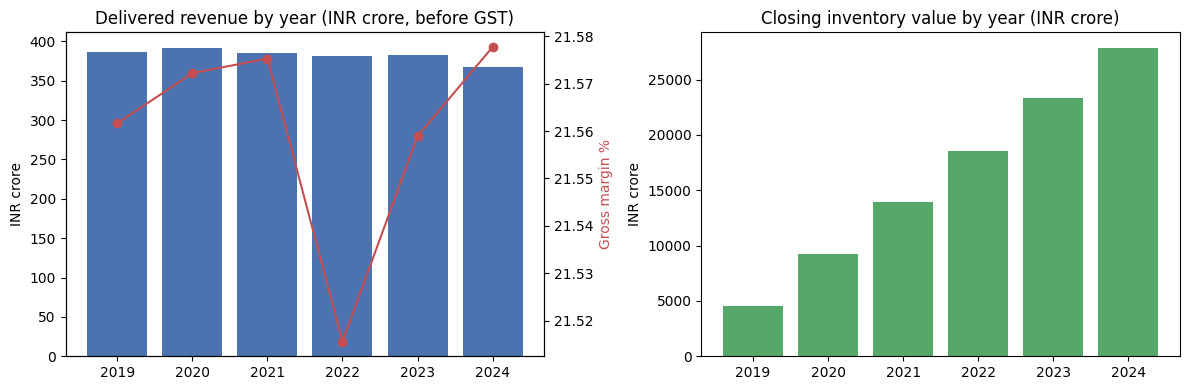

In [11]:
yrs = sales[sales.period != "2019-2024"]
inv_y = inv[inv.period != "2019-2024"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].bar(yrs["period"], yrs["revenue_cr"], color="#4C72B0")
ax[0].set_title("Delivered revenue by year (INR crore, before GST)")
ax[0].set_ylabel("INR crore")
ax2 = ax[0].twinx()
ax2.plot(yrs["period"], yrs["gross_margin_pct"], color="#C44E52", marker="o")
ax2.set_ylabel("Gross margin %", color="#C44E52")

ax[1].bar(inv_y["period"], inv_y["closing_inventory_value_cr"], color="#55A868")
ax[1].set_title("Closing inventory value by year (INR crore)")
ax[1].set_ylabel("INR crore")

plt.tight_layout()
plt.show()

**Reading the output.** Left: revenue bars with the gross-margin line. Look for the revenue trend across years and a steady margin. Right: year-end inventory value. A value that keeps rising while revenue stays flat is the overstock story in one picture, and it motivates Weeks 5 and 10.

In [12]:
latest = tracker[["area", "kpi", "unit", "2024 (latest)", "2019-2024"]]
latest[latest["kpi"].isin([
    "Revenue (before GST)", "Gross margin %", "SO cancellation rate", "Collection rate",
    "On-time delivery rate", "Supplier concentration (HHI)", "Inventory turnover",
    "Days of inventory on hand", "Stock-to-max ratio", "Excess inventory value (above max)",
    "Receipts-to-issues ratio"])].round(2)

period,area,kpi,unit,2024 (latest),2019-2024
2,Sales & Finance,Revenue (before GST),INR crore,367.80,2295.90
5,Sales & Finance,Gross margin %,%,21.58,21.56
7,Sales & Finance,SO cancellation rate,%,10.86,9.84
11,Sales & Finance,Collection rate,%,79.90,79.70
24,Supplier & Procurement,On-time delivery rate,%,84.87,84.90
30,Supplier & Procurement,Supplier concentration (HHI),index,1252.39,1250.46
35,Product & Inventory,Inventory turnover,times per year,0.01,0.04
36,Product & Inventory,Days of inventory on hand,days,32394.93,17098.51
38,Product & Inventory,Stock-to-max ratio,ratio,330.31,192.48
40,Product & Inventory,Excess inventory value (above max),INR crore,27793.34,16159.25


**Reading the output.** A short list of the headline KPIs for the latest year and the whole period. Use it as the base for the Phase 1 summary report.

## 8. Summary

| Item | Result |
|---|---|
| KPI tracker | One table with KPIs across 5 areas, per year 2019-2024, the whole period and the latest year (2024) |
| Files | `docs/kpi_tracker.csv` and `docs/kpi_tracker.xlsx` |
| Method | Delivered revenue only; cancelled records excluded from timing; ambiguous invoices excluded from payment KPIs |
| Limits | DSO is a proxy; stock excludes adjustments (direction unknown); branch costs assumed constant across years |

**Status: COMPLETED** once the notebook runs top to bottom and the tracker files exist.

**Next.** Use these numbers in `reports/phase1_summary.docx`, then build the data dictionary (A6).

In [13]:
con.close()
print("Connection closed.")

Connection closed.
